In [1]:
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

x = torch.linspace(-3, 3, 121, requires_grad=True)

relu_output = F.relu(x)
gelu_output = F.gelu(x)

relu_grad = torch.autograd.grad(
    relu_output.sum(), x, retain_graph=True
)[0]

gelu_grad = torch.autograd.grad(
    gelu_output.sum(), x
)[0]

print("ReLU output:", relu_output[:5])
print("GELU output:", gelu_output[:5])

ReLU output: tensor([0., 0., 0., 0., 0.], grad_fn=<SliceBackward0>)
GELU output: tensor([-0.0040, -0.0047, -0.0054, -0.0062, -0.0072], grad_fn=<SliceBackward0>)


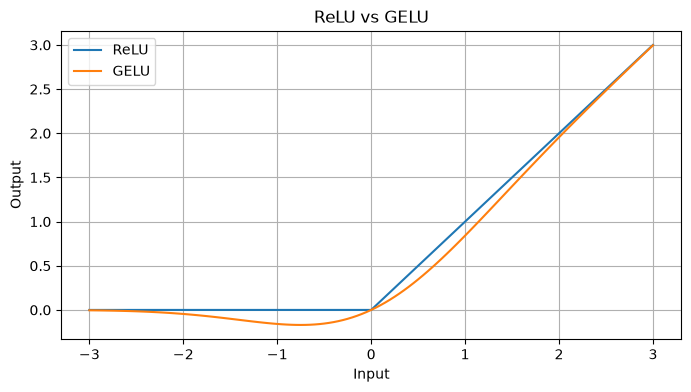

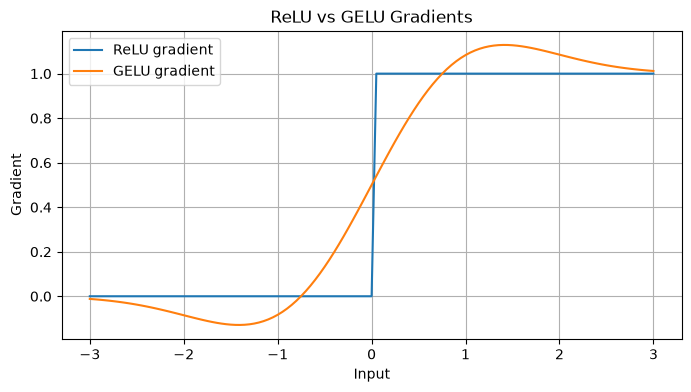

In [2]:
plt.figure(figsize=(8, 4))
plt.plot(x.detach(), relu_output.detach(), label="ReLU")
plt.plot(x.detach(), gelu_output.detach(), label="GELU")
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("ReLU vs GELU")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(x.detach(), relu_grad.detach(), label="ReLU gradient")
plt.plot(x.detach(), gelu_grad.detach(), label="GELU gradient")
plt.xlabel("Input")
plt.ylabel("Gradient")
plt.title("ReLU vs GELU Gradients")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
torch.manual_seed(42)

dropout = nn.Dropout(p=0.5)
x = torch.ones(1000)

# Training mode
dropout.train()
train_output_1 = dropout(x)
train_output_2 = dropout(x)

print("Input mean:", x.mean().item())
print("Training output mean:", train_output_1.mean().item())
print("Unique output values:", torch.unique(train_output_1))
print("Two outputs equal:", torch.equal(train_output_1, train_output_2))

dropout.eval()
eval_output = dropout(x)

print("Evaluation output equals input:", torch.equal(eval_output, x))

assert torch.equal(eval_output, x)

Input mean: 1.0
Training output mean: 1.0140000581741333
Unique output values: tensor([0., 2.])
Two outputs equal: False
Evaluation output equals input: True


In [5]:
model = nn.Sequential(
    nn.Linear(4, 8),
    nn.GELU(),
    nn.Dropout(p=0.25),
    nn.Linear(8, 2)
)

batch = torch.randn(5, 4)

# Training mode
model.train()
train_output_1 = model(batch)
train_output_2 = model(batch)

print("Training output shape:", train_output_1.shape)
print("Training outputs equal:", torch.allclose(
    train_output_1, train_output_2
))

# Evaluation mode
model.eval()
with torch.no_grad():
    eval_output_1 = model(batch)
    eval_output_2 = model(batch)

print("Evaluation output shape:", eval_output_1.shape)
print("Evaluation outputs equal:", torch.allclose(
    eval_output_1, eval_output_2
))

assert torch.allclose(eval_output_1, eval_output_2)

Training output shape: torch.Size([5, 2])
Training outputs equal: False
Evaluation output shape: torch.Size([5, 2])
Evaluation outputs equal: True
